# COMM 486T Assignment 3 Supporting Analysis File

This is an Jupyter Notebook file that is created to accompany the 2-slide pdf that combines my overall conclusions for Assignment 3. 

As a student also in the data science minor at UBC, I thought that using a Jupyter Notebook was best way to present my data collection in a clear and informative way. 

I am also familiar with the usage of Jupyter Notebooks which also factored in my decision making for a support analysis file.


## AI Attribution

 This notebook was built with AI assistance (Muse and Cursor). I directed the analysis, verified the results, and wrote the explanations in my own words.

## Step 1: Load data from CSV Stored on Github

I pulled the aligned one-minute panel from a CSV I have uploaded to GitHub. I can do this by importing the pandas library.

The CSV was built by pulling the BTC/USD data that comes from Coinbase 1-minute candles using the close price. The BTC/CAD data was pulled from the NDAX GetTickerHistory API using the quote midpoint, and the USD/CAD data was pulled from the Dukascopy tick feed aggregated to 1-minute last-mid prices. 

All three series are aligned on a common UTC minute grid for Oct 28, 2026, 12:00–20:00 UTC (480 rows), with NDAX bars shifted back 60 seconds because they are stamped at the end of the minute. 

I assign the CSV I pulled from Github onto the variable "df".


In [11]:
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/Shobby9451/COMM-486-Assignment-3/"
    "refs/heads/main/aligned.csv"
)

df = pd.read_csv(DATA_URL, parse_dates=["ts"])
print("Rows:", len(df))
df.head()


Rows: 480


,ts,btcusd_open,btcusd_high,btcusd_low,btcusd_close,btcusd_vol,btccad_open,btccad_high,btccad_low,btccad_close,...,implied_usdcad_close,disc_bps,disc_bps_close,btcusd_ask,btcusd_bid,edgeA_exec,edgeB_exec,edge_exec,net_edge,ndax_mid_changed
0,2026-10-28 12:00:00+00:00,81215.30,81215.30,81200.00,81215.09,2.459778,113935.63,113935.63,113935.63,113935.63,...,1.402887,-25.312717,-3.723476,81223.211509,81206.968491,-48.322632,2.296844,2.296844,-47.703156,False
1,2026-10-28 12:01:00+00:00,81215.09,81225.03,81192.50,81198.12,2.479504,113935.63,113935.63,113935.63,113935.63,...,1.403181,-23.690117,-2.097364,81206.239812,81190.000188,-46.668298,0.705667,0.705667,-49.294333,False
2,2026-10-28 12:02:00+00:00,81198.12,81198.13,81113.39,81127.92,2.307028,113935.63,113935.63,113935.63,113935.63,...,1.404395,-13.919174,7.694727,81136.032792,81119.807208,-36.919905,-9.079630,-9.079630,-59.079630,False
3,2026-10-28 12:03:00+00:00,81127.92,81127.92,81073.05,81106.80,5.714524,113935.63,113935.63,113935.63,113935.63,...,1.404761,-10.144230,11.477841,81114.910680,81098.689320,-33.189216,-12.890612,-12.890612,-62.890612,False
4,2026-10-28 12:04:00+00:00,81106.81,81106.81,81083.10,81086.76,1.367732,113935.63,113935.63,113935.63,113935.63,...,1.405108,-7.390448,14.237584,81094.868676,81078.651324,-30.441798,-15.642891,-15.642891,-65.642891,False


## Step 2: Implied FX Rate and Gap

I create a new column named "implied" that represents the implied USD/CAD exchange rate by dividing the bitcoin price in CAD by the bitcoin price in USD.

Then, I can divide the new "implied" column by the observed exchange rate column "usdcad_mid", subtract 1, and multiply the result by 10000 to get the gap in basis points across the minutes of the time frame.

I then output the mean gap, max gap, and min gap throughout the 12:00 - 20:00 UTC window from which the data was pulled from.

In [12]:
df["implied"] = df["btccad_mid"] / df["btcusd_close"]
df["disc_bps"] = (df["implied"] / df["usdcad_mid"] - 1) * 10000

print("Mean gap (bps):", round(df["disc_bps"].mean(), 1))
print("Max gap (bps):", round(df["disc_bps"].max(), 1))
print("Min gap (bps):", round(df["disc_bps"].min(), 1))


Mean gap (bps): 9.8
Max gap (bps): 51.8
Min gap (bps): -34.0


## Step 3: BoC and Fed Windows

I start by splitting the day into the two announcement windows. The Bank of Canada window is the rows where "ts" falls between 13:00 and 15:00 UTC, so I pull those into a table called "boc". The Fed window works the same way, 17:30 to 19:30 UTC, and that becomes "fed".

Once I have the two windows, I look at each one in turn. For each, I count the minutes where the gap in "disc_bps" is bigger than 25 basis points either way, and I keep that count in "over".

From there I print the window name, the mean gap, the max gap, and how many minutes out of the window's total had a gap over 25 bps.

In [13]:
boc = df[(df["ts"] >= "2026-10-28 13:00:00+00:00") & (df["ts"] < "2026-10-28 15:00:00+00:00")]
fed = df[(df["ts"] >= "2026-10-28 17:30:00+00:00") & (df["ts"] < "2026-10-28 19:30:00+00:00")]

for name, w in [("BoC window", boc), ("Fed window", fed)]:
    over = (w["disc_bps"].abs() > 25).sum()
    print(name)
    print("  Mean gap (bps):", round(w["disc_bps"].mean(), 1))
    print("  Max gap (bps):", round(w["disc_bps"].max(), 1))
    print("  Minutes with |gap| > 25 bps:", over, "of", len(w))


BoC window
  Mean gap (bps): 20.6
  Max gap (bps): 51.8
  Minutes with |gap| > 25 bps: 42 of 120
Fed window
  Mean gap (bps): -4.7
  Max gap (bps): 21.3
  Minutes with |gap| > 25 bps: 8 of 120


## Step 4: Backtesting the Trading Rules

First I set the trade size to 10,000 in "NOTIONAL" and make an empty list called "trades" to hold each trade.

From there I walk through the table one minute at a time, looking at the current row and the next one, which I call "row" and "nxt". The next row is the execution minute, one minute later, since that's when the trade actually happens.

If the gap in "disc_bps" is 25 basis points or smaller, I skip that minute. 

When the gap is positive, Bitcoin is expensive in Canada, so I buy it with USD and sell it for CAD. I work out the gross profit from the next minute's closing prices and mid price, and the executable price from the next minute's bid and ask. A negative gap just flips it around: buy with CAD, sell for USD, same calculations.

Once I have the executable price, I take off the 0.5% fees, multiply by the trade size, and that gives me the net profit. I add the gross and net profit for that trade to the "trades" list.

When the loop is done, I turn the list into a table called "trades_df". Then I print the number of trades, the total gross profit, the total net profit, and how many trades won after costs.


In [14]:
NOTIONAL = 10_000
trades = []

for i in range(len(df) - 1):
    row, nxt = df.iloc[i], df.iloc[i + 1]
    if abs(row["disc_bps"]) <= 25:
        continue
    if row["disc_bps"] > 0:
        gross = NOTIONAL * (nxt["btccad_close"] / (nxt["btcusd_close"] * nxt["usdcad_mid"]) - 1)
        exe = nxt["btccad_bid"] / (nxt["btcusd_close"] * 1.0001 * nxt["usdcad_ask"])
    else:
        gross = NOTIONAL * (nxt["btcusd_close"] * nxt["usdcad_mid"] / nxt["btccad_close"] - 1)
        exe = (nxt["btcusd_close"] * 0.9999) * nxt["usdcad_bid"] / nxt["btccad_ask"]
    net = NOTIONAL * (exe * (1 - 0.005) - 1)
    trades.append({"gross_cad": gross, "net_cad": net})

trades_df = pd.DataFrame(trades)
print("Number of trades:", len(trades_df))
print("Gross profit (CAD):", round(trades_df["gross_cad"].sum(), 2))
print("Net profit (CAD):", round(trades_df["net_cad"].sum(), 2))
print("Winning trades after costs:", (trades_df["net_cad"] > 0).sum())


Number of trades: 85
Gross profit (CAD): 4438.49
Net profit (CAD): -3050.72
Winning trades after costs: 0


## Step 5: Cost-aware Rule

The "net_edge" column is the net profit in basis points for each minute, after spreads and fees. I count how many minutes it is greater than 0 and keep that count in "profitable", which tells me how many minutes were actually worth trading.

From there I print that count, and then the best "net_edge" of the day, rounded to one decimal place.


In [15]:
profitable = (df["net_edge"] > 0).sum()
print("Minutes profitable after costs:", profitable)
print("Best net_edge (bps):", round(df["net_edge"].max(), 1))


Minutes profitable after costs: 0
Best net_edge (bps): -8.3


## Step 6: Visualizing the Data

I bring in "matplotlib.pyplot" as "plt" and "matplotlib.dates" as "mdates" to make the charts, and I set the style first so the grid is on and the background is white.

For the first chart I make a figure 10 inches wide and 3.5 tall, then plot "ts" on the x-axis against "disc_bps" on the y-axis as a blue line. I add a solid line at 0 and dashed lines at 25 and -25, which are the trigger levels, label the y-axis "Gap (basis points)" and the x-axis "Time (UTC), Oct 28 2026", and format the x-axis labels as hours and minutes. From there I tighten the layout and show the chart right in the notebook.

For the second chart I add up the "gross_cad" and "net_cad" columns from "trades_df" into "gross_sum" and "net_sum", then make a smaller figure, 5 by 3.5 inches. I draw two bars from those totals, green for "Gross" and red for "Net", add a solid line at 0, and label the y-axis "Profit (CAD)". Then I tighten the layout and show that chart in the notebook too.


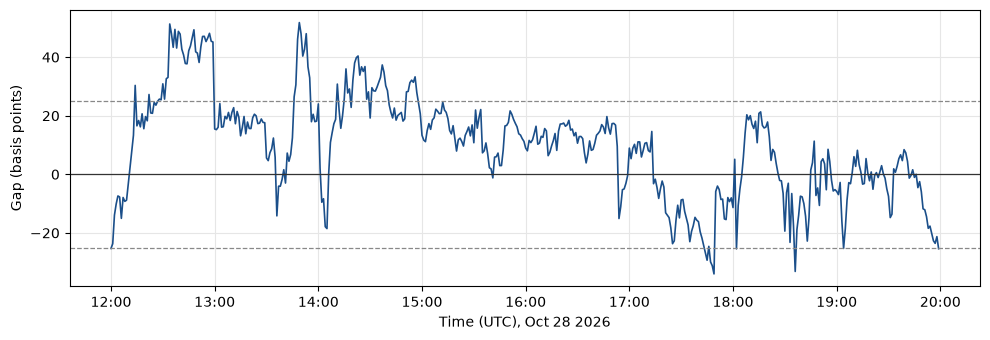

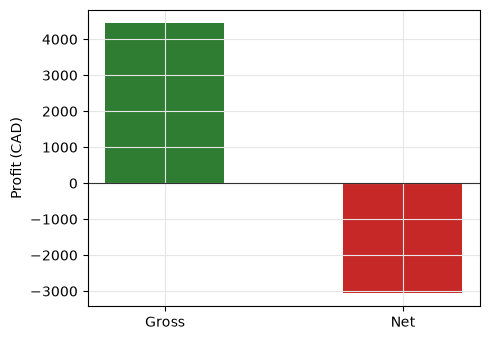

In [19]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"axes.grid": True, "grid.color": "#E6E6E6", "figure.facecolor": "white"})

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(df["ts"], df["disc_bps"], color="#1B4F8A", linewidth=1.2)
ax.axhline(0, color="#333333", linewidth=0.9)
ax.axhline(25, color="#888888", linestyle="--", linewidth=0.9)
ax.axhline(-25, color="#888888", linestyle="--", linewidth=0.9)
ax.set_ylabel("Gap (basis points)")
ax.set_xlabel("Time (UTC), Oct 28 2026")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout()
plt.show()

gross_sum = trades_df["gross_cad"].sum()
net_sum = trades_df["net_cad"].sum()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Gross", "Net"], [gross_sum, net_sum], color=["#2E7D32", "#C62828"], width=0.5)
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_ylabel("Profit (CAD)")
fig.tight_layout()
plt.show()
